## Распределения train

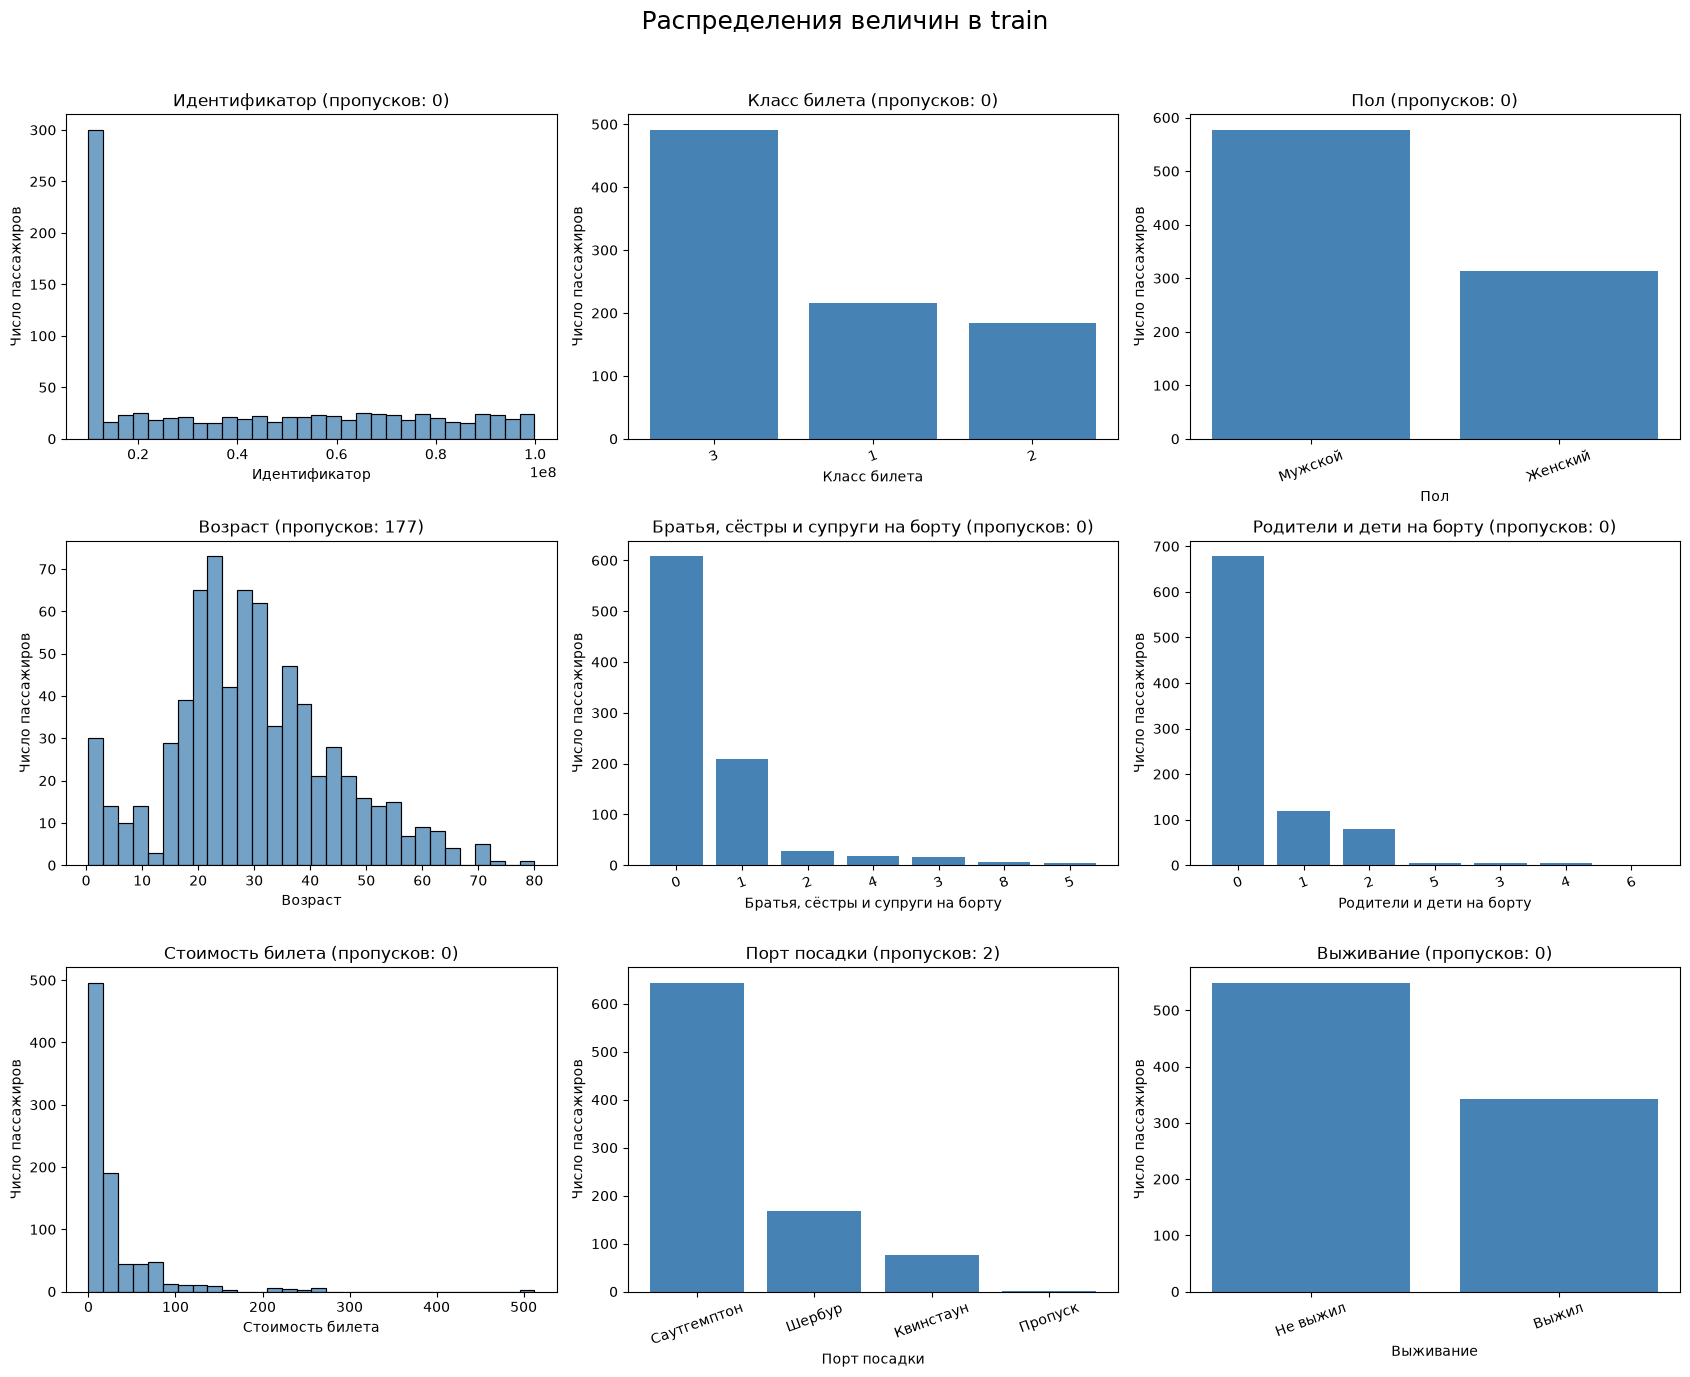

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка train
train = pd.read_csv("data/train.csv")

# Распределения признаков
labels = {
    "Id": "Идентификатор",
    "Pclass": "Класс билета",
    "Sex": "Пол",
    "Age": "Возраст",
    "SibSp": "Братья, сёстры и супруги на борту",
    "Parch": "Родители и дети на борту",
    "Fare": "Стоимость билета",
    "Embarked": "Порт посадки",
    "Survived": "Выживание",
}
categories = {
    "Sex": {"male": "Мужской", "female": "Женский"},
    "Embarked": {"S": "Саутгемптон", "C": "Шербур", "Q": "Квинстаун"},
    "Survived": {0: "Не выжил", 1: "Выжил"},
}
discrete = ["Pclass", "Sex", "SibSp", "Parch", "Embarked", "Survived"]
fig, axes = plt.subplots(3, 3, figsize=(17, 14))
for column, ax in zip(train.columns, axes.flat):
    if column in discrete:
        values = train[column].replace(categories.get(column, {}))
        counts = values.value_counts(dropna=False).rename(index={float("nan"): "Пропуск"})
        counts.index = ["Пропуск" if pd.isna(value) else str(value) for value in counts.index]
        ax.bar(counts.index, counts.values, color="steelblue")
        ax.tick_params(axis="x", labelrotation=20)
    else:
        sns.histplot(data=train, x=column, bins=30, ax=ax, color="steelblue")
    ax.set_title(f"{labels[column]} (пропусков: {train[column].isna().sum()})")
    ax.set_xlabel(labels[column])
    ax.set_ylabel("Число пассажиров")
fig.suptitle("Распределения величин в train", fontsize=18)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


## Заполнение возраста

In [2]:
# Медиана возраста
age_median = train["Age"].median()
train["Age"] = train["Age"].fillna(age_median)

print("Медиана возраста:", age_median)
print("Пропусков возраста:", train["Age"].isna().sum())


Медиана возраста: 28.0
Пропусков возраста: 0


In [3]:
# Новый признак
train["around_whealth"] = (train["Parch"] + train["SibSp"]) * train["Fare"]
display(train[["Parch", "SibSp", "Fare", "around_whealth"]].head())


,Parch,SibSp,Fare,around_whealth
0,0,1,7.2500,7.2500
1,0,1,71.2833,71.2833
2,0,0,7.9250,0.0000
3,0,0,51.8625,0.0000
4,1,3,21.0750,84.3000


## Кодирование категорий

In [4]:
train = train.drop(columns=["Id"], errors="ignore")

# OHE категорий
categorical_columns = ["Sex", "Embarked"]
train_encoded = pd.get_dummies(
    train, columns=categorical_columns, dummy_na=True, dtype=int
)
display(train_encoded.head())


,Pclass,Age,SibSp,Parch,Fare,Survived,around_whealth,Sex_female,Sex_male,Sex_nan,Embarked_C,Embarked_Q,Embarked_S,Embarked_nan
0,3,22.0,1,0,7.2500,0,7.2500,0,1,0,0,0,1,0
1,1,38.0,1,0,71.2833,1,71.2833,1,0,0,1,0,0,0
2,3,26.0,0,0,7.9250,1,0.0000,1,0,0,0,0,1,0
3,1,54.0,0,0,51.8625,0,0.0000,0,1,0,0,0,1,0
4,3,2.0,3,1,21.0750,0,84.3000,0,1,0,0,0,1,0


## Базовая модель

In [5]:
from sklearn.dummy import DummyClassifier

# Обучение базовой модели
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(train_encoded.drop(columns="Survived"), train_encoded["Survived"])

# Предсказания базовой модели
baseline_test = pd.read_csv("data/test.csv")
baseline_prediction = baseline.predict(pd.DataFrame(index=baseline_test.index))
baseline_submission = pd.DataFrame({
    "Id": baseline_test["Id"],
    "Survived": baseline_prediction,
})

# Сохранение посылки
baseline_sample = pd.read_csv("data/sample_submission.csv")
assert baseline_submission.columns.tolist() == baseline_sample.columns.tolist()
assert baseline_submission["Id"].equals(baseline_sample["Id"])
assert baseline_submission["Survived"].isin([0, 1]).all()
assert not baseline_submission.isna().any().any()
baseline_submission.to_csv("submission_baseline.csv", index=False)
print("Самый частый класс:", train_encoded["Survived"].mode().iloc[0])
print("Сохранён submission_baseline.csv, строк:", len(baseline_submission))
display(baseline_submission.head())


Самый частый класс: 0
Сохранён submission_baseline.csv, строк: 1000


,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,0
3,16342593,0
4,10829305,0


## Версии датасета

Сначала заполнение пропусков и масштабирование числовых признаков в одной из веток, затем полиномы второй степени. OHE-столбцы остаются без изменений. Все преобразования обучаются на train.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer

# Исходные признаки
X_train = train_encoded.drop(columns="Survived")
y_train = train_encoded["Survived"]
test = pd.read_csv("data/test.csv")
test_features = test.drop(columns=["Id", "Survived"], errors="ignore").copy()
test_features["Age"] = test_features["Age"].fillna(age_median)
test_features["around_whealth"] = (test_features["Parch"] + test_features["SibSp"]) * test_features["Fare"]
X_test = pd.get_dummies(
    test_features, columns=categorical_columns, dummy_na=True, dtype=int
).reindex(columns=X_train.columns, fill_value=0)
numeric_columns = ["Pclass", "Age", "SibSp", "Parch", "Fare", "around_whealth"]

# Без масштабирования
unscaled_transformer = ColumnTransformer([
    ("polynomial", make_pipeline(
        SimpleImputer(strategy="median"),
        PolynomialFeatures(degree=2, include_bias=False),
    ), numeric_columns),
], remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
X_train_unscaled = unscaled_transformer.fit_transform(X_train)
X_test_unscaled = unscaled_transformer.transform(X_test)

# Масштабирование перед полиномами
scaled_transformer = ColumnTransformer([
    ("polynomial", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
    ), numeric_columns),
], remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
X_train_scaled = scaled_transformer.fit_transform(X_train)
X_test_scaled = scaled_transformer.transform(X_test)

print("Без масштабирования:", X_train_unscaled.shape, X_test_unscaled.shape)
print("Масштабирование перед полиномами:", X_train_scaled.shape, X_test_scaled.shape)
assert X_train_unscaled.columns.equals(X_train_scaled.columns)
assert X_train_scaled.notna().all().all()
assert X_test_scaled.notna().all().all()


Без масштабирования: (891, 34) (1000, 34)
Масштабирование перед полиномами: (891, 34) (1000, 34)


## Характеристики датасетов

In [7]:
# Описательная статистика
def describe_dataset(data):
    summary = data.describe().T.rename(columns={
        "count": "Количество", "mean": "Среднее", "std": "Стандартное отклонение",
        "min": "Минимум", "25%": "Квартиль 25%", "50%": "Медиана",
        "75%": "Квартиль 75%", "max": "Максимум",
    })
    summary["Пропуски"] = data.isna().sum()
    summary["Уникальных значений"] = data.nunique()
    summary["Асимметрия"] = data.skew()
    summary["Эксцесс"] = data.kurt()
    summary["Форма"] = [
        "Константа" if data[column].nunique() <= 1 else
        "Бинарное" if data[column].nunique() == 2 else
        "Правая асимметрия" if data[column].skew() > 0.5 else
        "Левая асимметрия" if data[column].skew() < -0.5 else
        "Примерно симметричное"
        for column in data.columns
    ]
    return summary

unscaled_summary = describe_dataset(X_train_unscaled)
scaled_summary = describe_dataset(X_train_scaled)
print("Без масштабирования")
display(unscaled_summary.round(3))
print("С масштабированием")
display(scaled_summary.round(3))


Без масштабирования


,Количество,Среднее,Стандартное отклонение,Минимум,Квартиль 25%,Медиана,Квартиль 75%,Максимум,Пропуски,Уникальных значений,Асимметрия,Эксцесс,Форма
Pclass,891.0,2.309,0.836,1.000,2.000,3.000,3.000,3.000,0,3,-0.631,-1.280,Левая асимметрия
Age,891.0,29.362,13.020,0.420,22.000,28.000,35.000,80.000,0,88,0.510,0.994,Правая асимметрия
SibSp,891.0,0.523,1.103,0.000,0.000,0.000,1.000,8.000,0,7,3.695,17.880,Правая асимметрия
Parch,891.0,0.382,0.806,0.000,0.000,0.000,0.000,6.000,0,7,2.749,9.778,Правая асимметрия
Fare,891.0,32.204,49.693,0.000,7.910,14.454,31.000,512.329,0,248,4.787,33.398,Правая асимметрия
around_whealth,891.0,46.522,133.265,0.000,0.000,0.000,40.425,1315.000,0,160,6.126,46.811,Правая асимметрия
Pclass^2,891.0,6.028,3.444,1.000,4.000,9.000,9.000,9.000,0,3,-0.444,-1.567,Примерно симметричное
Pclass Age,891.0,64.090,32.495,0.920,40.000,63.000,84.000,222.000,0,128,0.607,1.288,Правая асимметрия
Pclass SibSp,891.0,1.284,3.187,0.000,0.000,0.000,1.000,24.000,0,10,4.300,22.547,Правая асимметрия
Pclass Parch,891.0,0.893,2.131,0.000,0.000,0.000,0.000,18.000,0,10,3.647,17.603,Правая асимметрия


С масштабированием


,Количество,Среднее,Стандартное отклонение,Минимум,Квартиль 25%,Медиана,Квартиль 75%,Максимум,Пропуски,Уникальных значений,Асимметрия,Эксцесс,Форма
Pclass,891.0,-0.000,1.001,-1.566,-0.369,0.827,0.827,0.827,0,3,-0.631,-1.280,Левая асимметрия
Age,891.0,0.000,1.001,-2.224,-0.566,-0.105,0.433,3.892,0,88,0.510,0.994,Правая асимметрия
SibSp,891.0,0.000,1.001,-0.475,-0.475,-0.475,0.433,6.784,0,7,3.695,17.880,Правая асимметрия
Parch,891.0,0.000,1.001,-0.474,-0.474,-0.474,-0.474,6.974,0,7,2.749,9.778,Правая асимметрия
Fare,891.0,0.000,1.001,-0.648,-0.489,-0.357,-0.024,9.667,0,248,4.787,33.398,Правая асимметрия
around_whealth,891.0,0.000,1.001,-0.349,-0.349,-0.349,-0.046,9.524,0,160,6.126,46.811,Правая асимметрия
Pclass^2,891.0,1.000,0.849,0.136,0.685,0.685,0.685,2.453,0,3,0.971,-0.685,Правая асимметрия
Pclass Age,891.0,-0.340,1.046,-6.095,-0.659,-0.087,0.164,3.423,0,182,-1.285,4.310,Левая асимметрия
Pclass SibSp,891.0,0.083,0.883,-3.520,-0.393,-0.160,0.358,5.613,0,15,2.474,13.170,Правая асимметрия
Pclass Parch,891.0,0.018,0.959,-7.034,-0.392,-0.392,0.635,5.770,0,15,0.105,9.482,Примерно симметричное


## Распределения двух версий

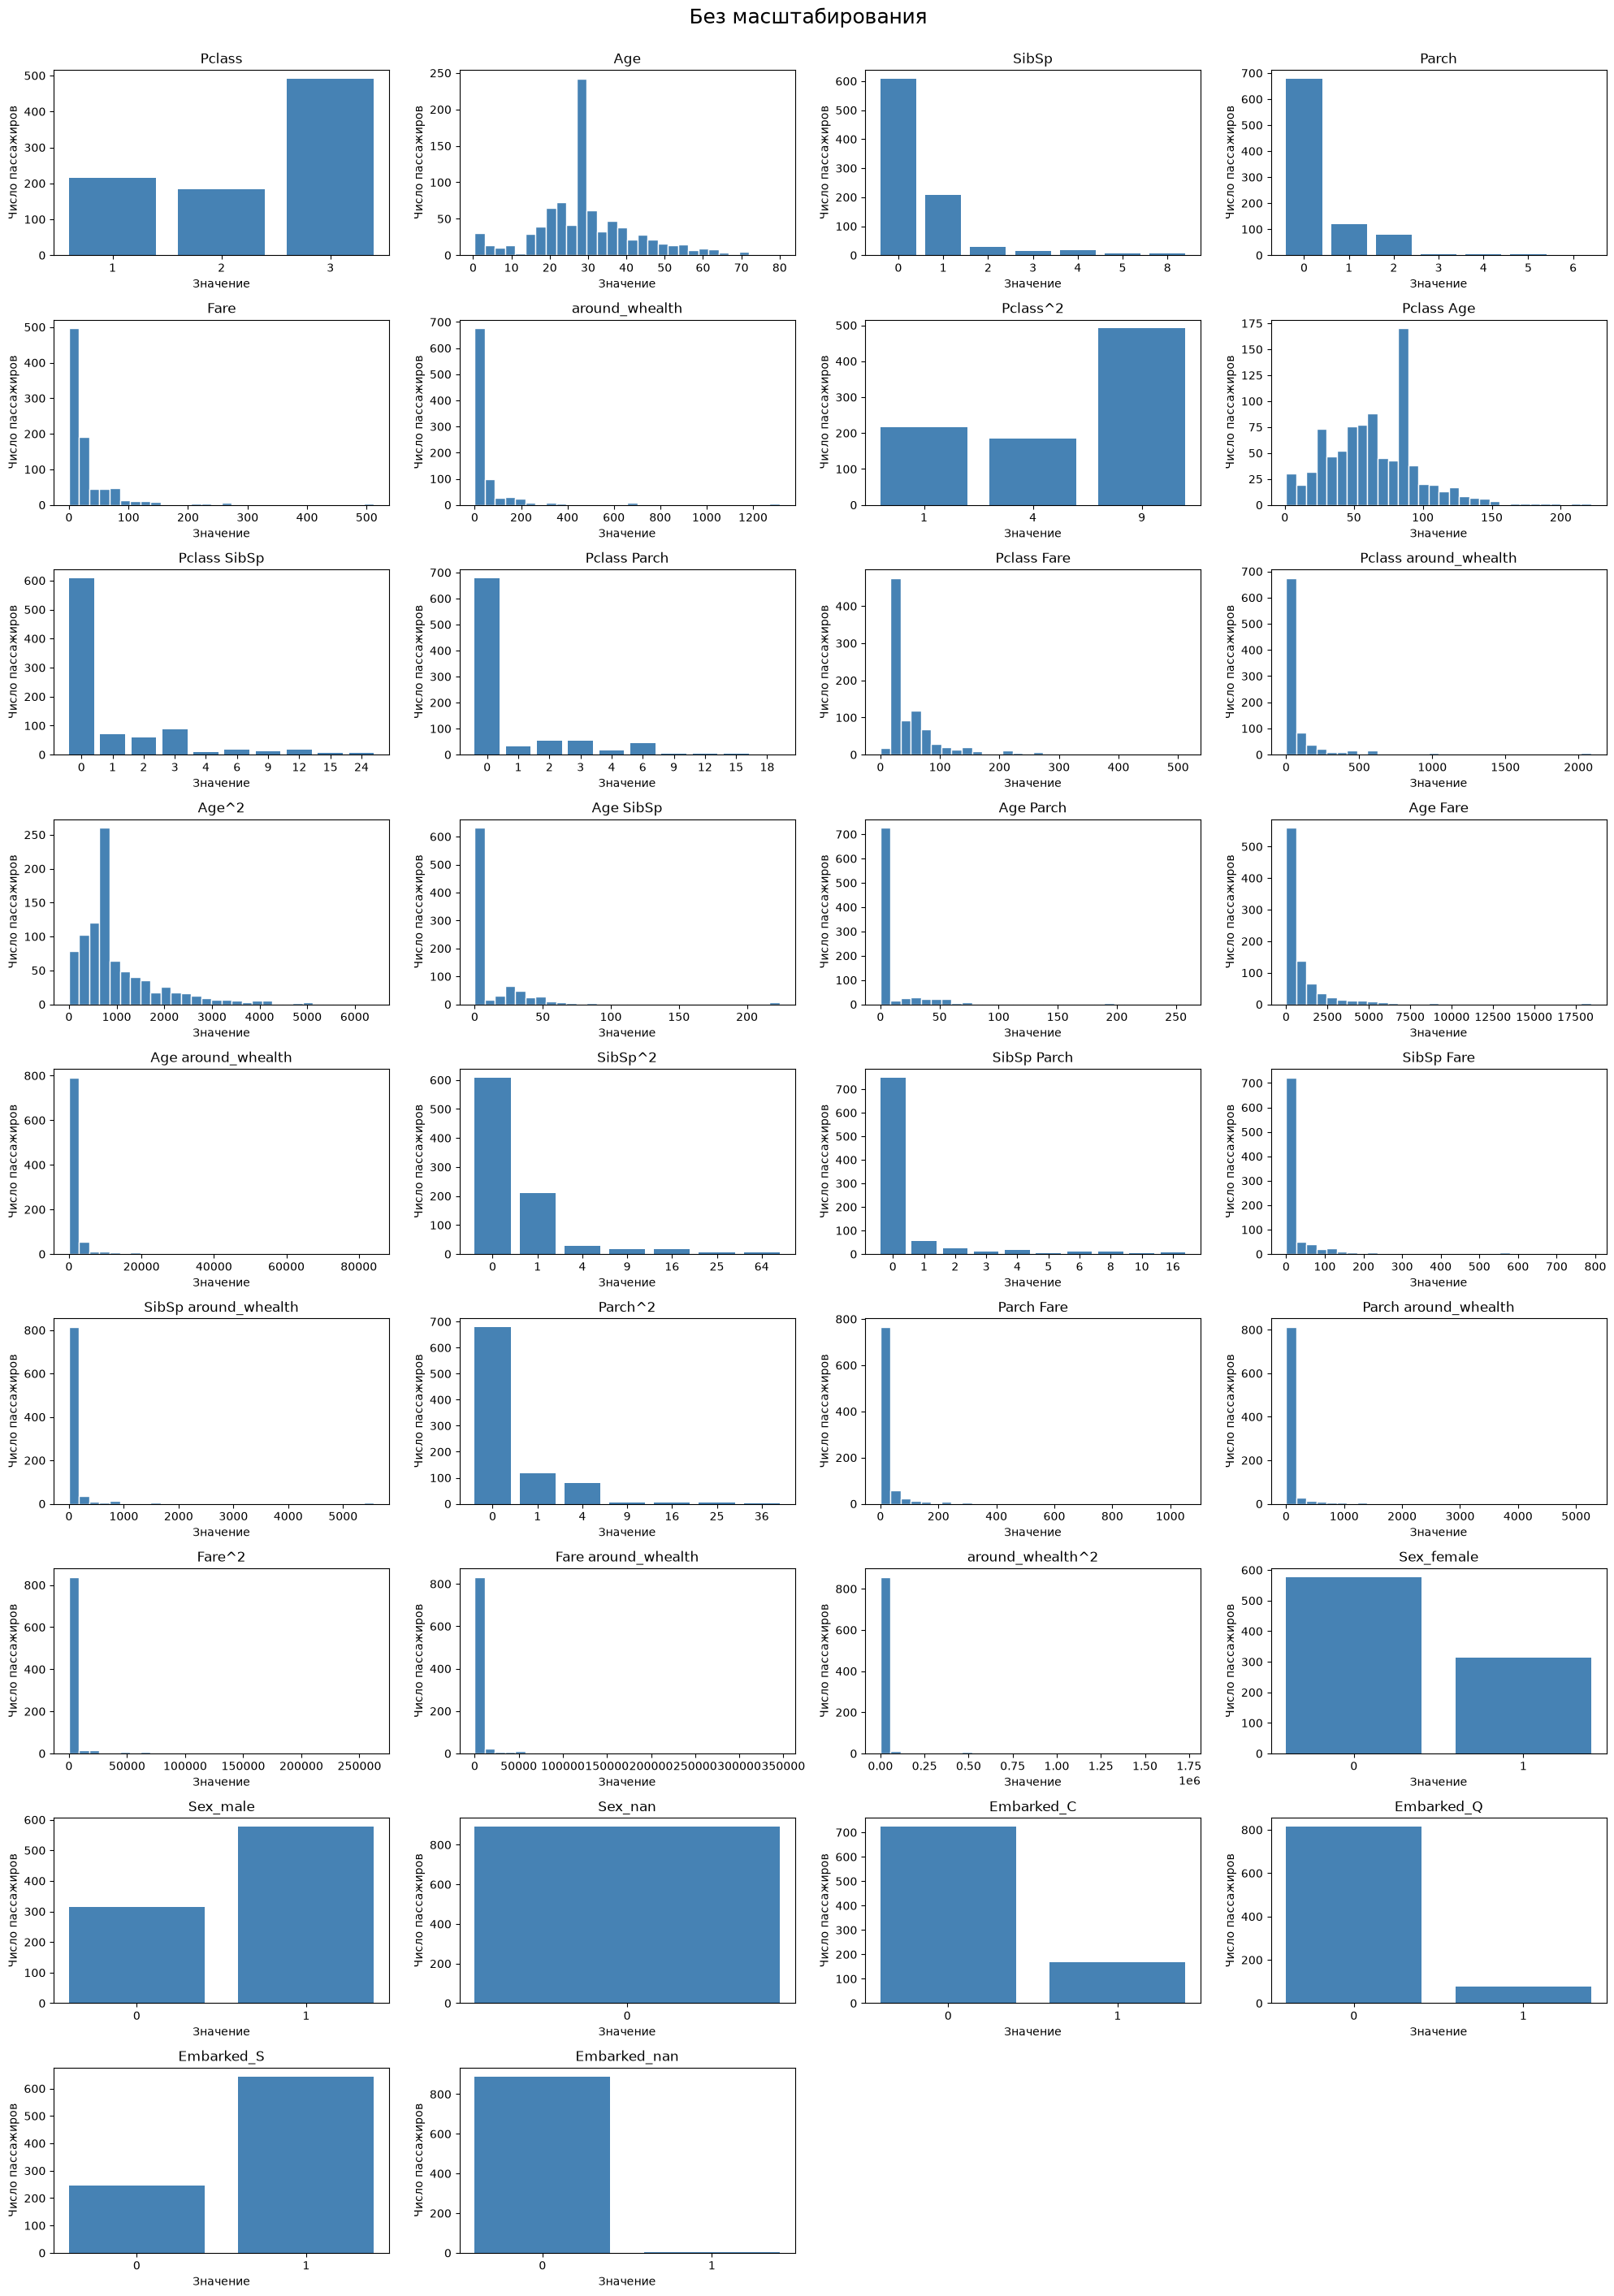

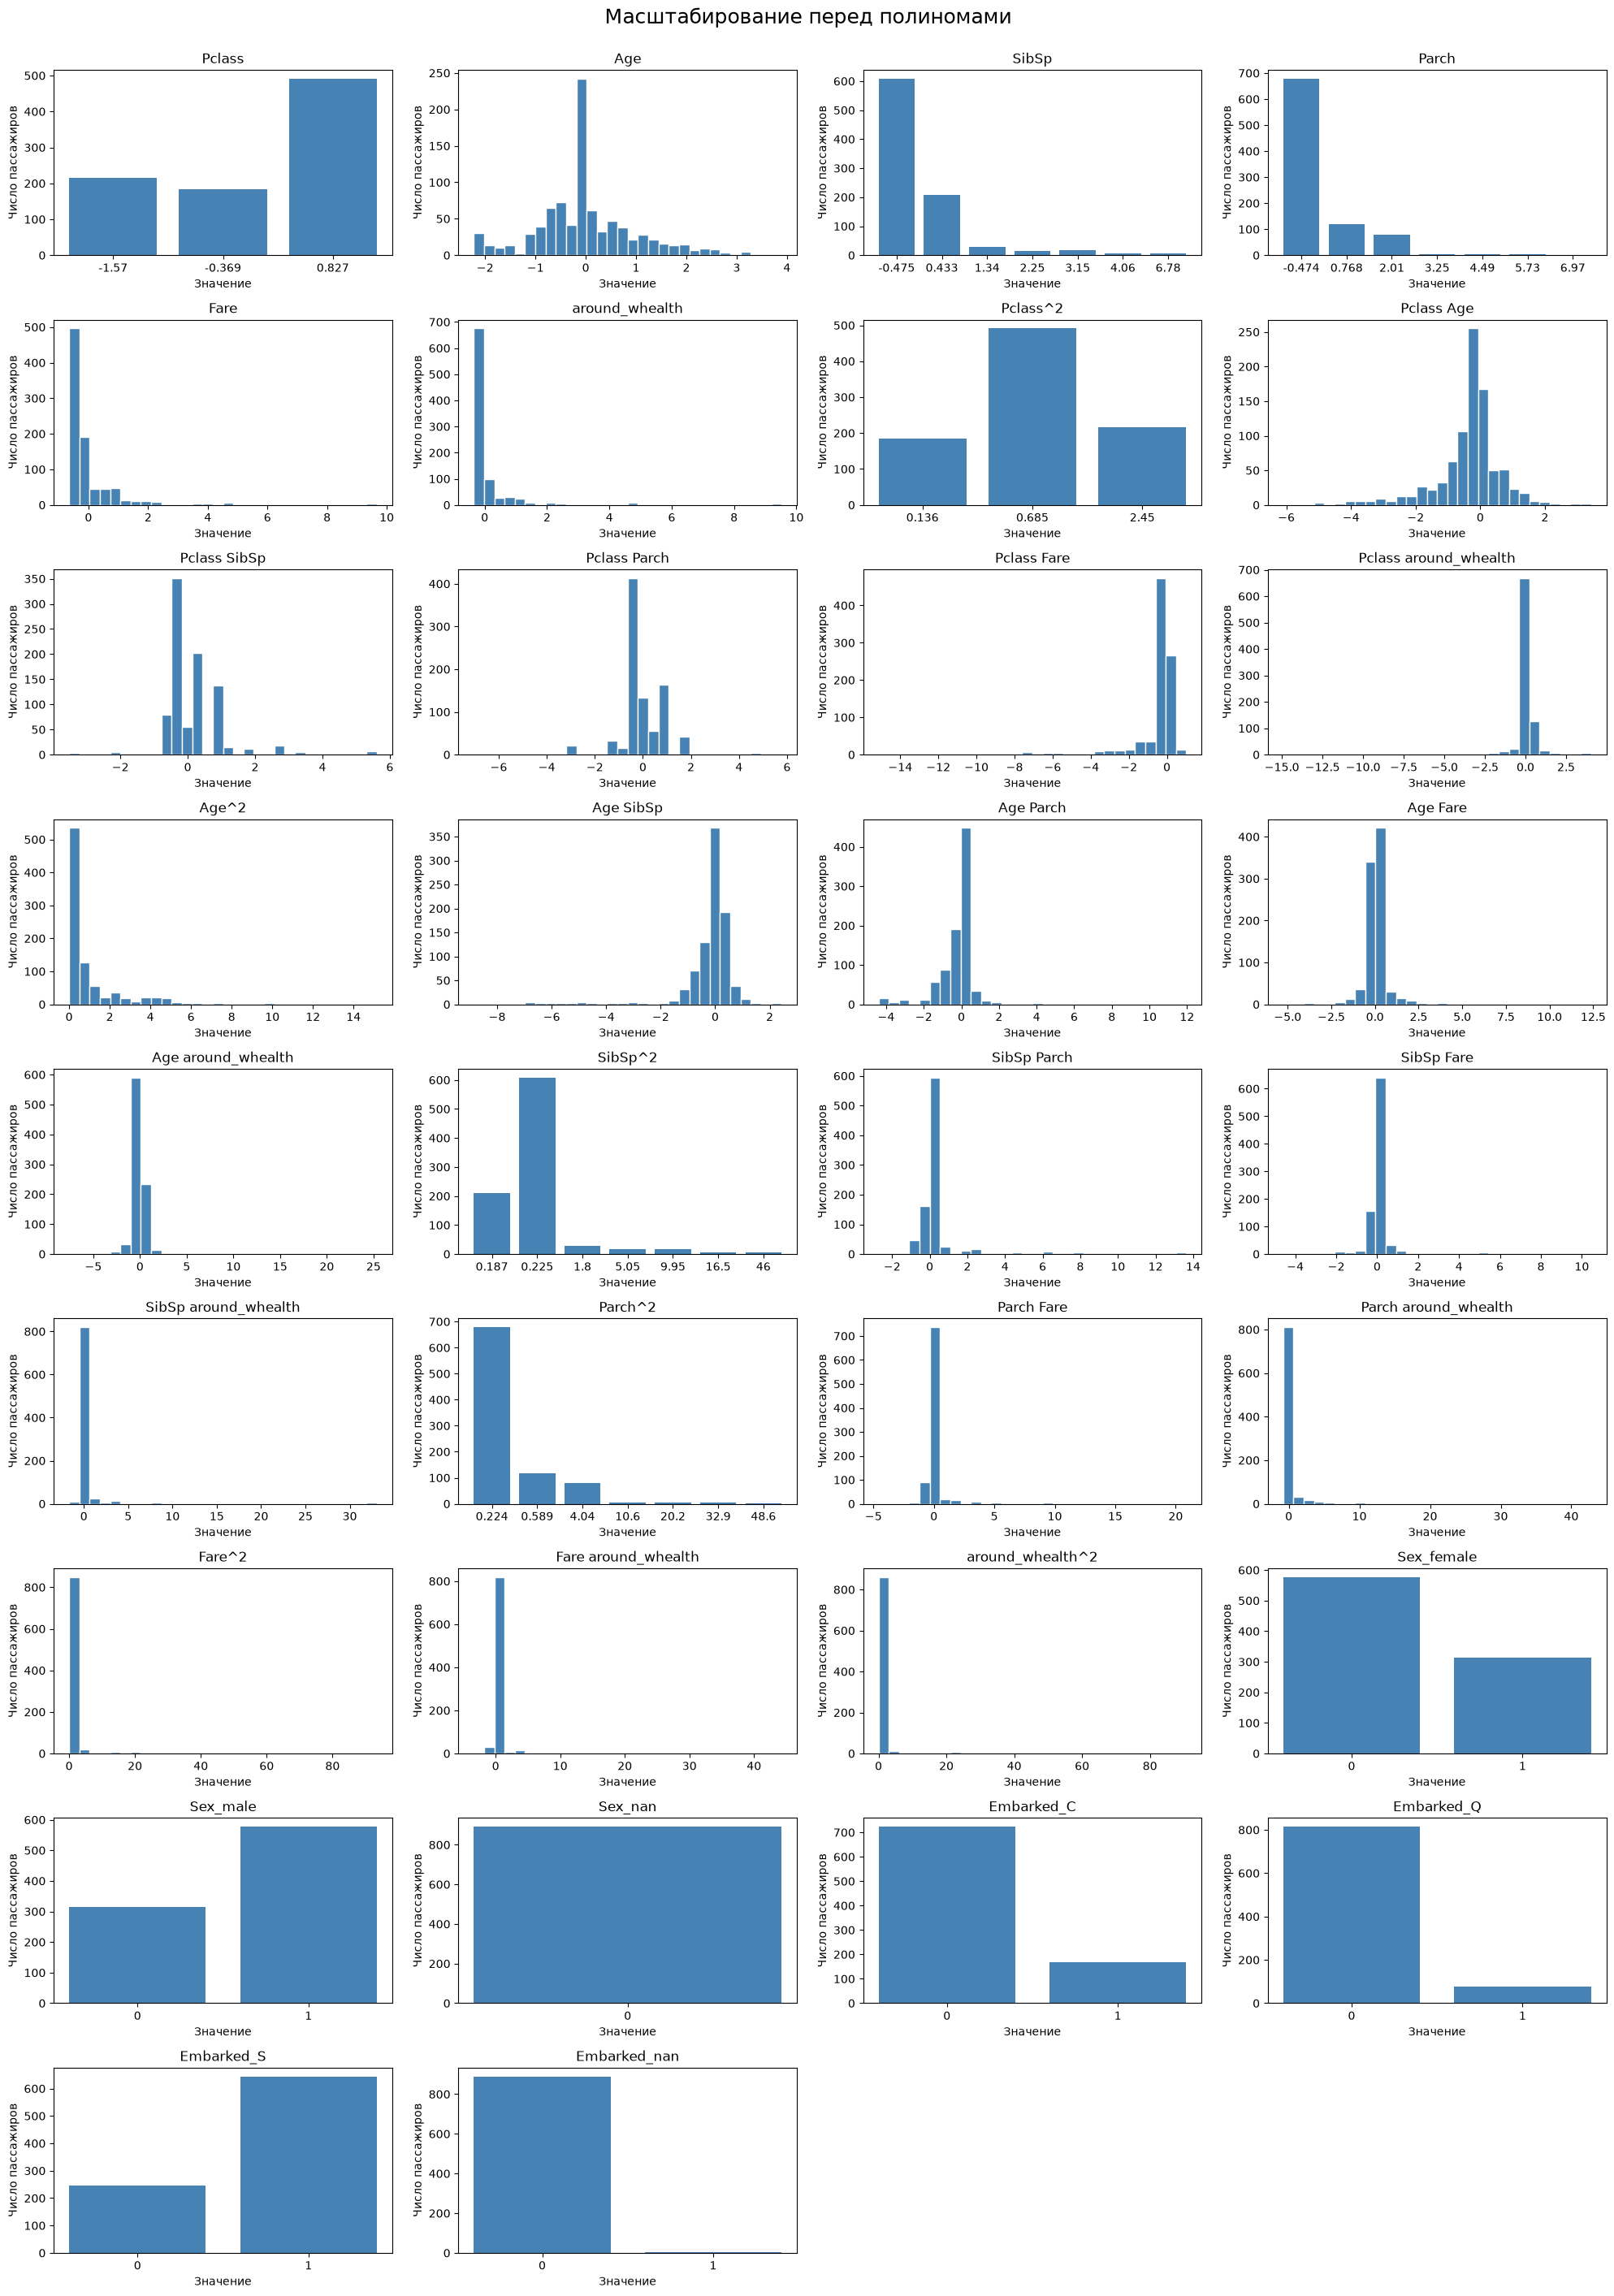

In [8]:
# Распределения признаков
import math

for title, data in [
    ("Без масштабирования", X_train_unscaled),
    ("Масштабирование перед полиномами", X_train_scaled),
]:
    rows = math.ceil(data.shape[1] / 4)
    fig, axes = plt.subplots(rows, 4, figsize=(20, rows * 3.2), squeeze=False)
    for column, ax in zip(data.columns, axes.flat):
        values = data[column]
        if values.nunique() <= 10:
            counts = values.value_counts().sort_index()
            ax.bar([f"{value:.3g}" for value in counts.index], counts.values, color="steelblue")
        else:
            ax.hist(values, bins=30, color="steelblue", edgecolor="white")
        ax.set_title(column)
        ax.set_xlabel("Значение")
        ax.set_ylabel("Число пассажиров")
    for ax in axes.flat[data.shape[1]:]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=18)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()


## Логистическая регрессия

In [9]:
from sklearn.linear_model import LogisticRegression

# Обучение модели
model = LogisticRegression(max_iter=5000, random_state=42)
model.fit(X_train_scaled, y_train)

# Предсказания
test_probability = model.predict_proba(X_test_scaled)[:, 1]
test_prediction = model.predict(X_test_scaled)
predictions = pd.DataFrame({
    "Id": test["Id"],
    "Survived": test_prediction,
    "Вероятность выживания": test_probability,
})
display(predictions.head())


,Id,Survived,Вероятность выживания
0,55586928,0,0.096111
1,24554381,0,0.272319
2,50120493,1,0.614631
3,16342593,0,0.044555
4,10829305,0,0.068677


## Посылка Kaggle

In [10]:
# Сохранение предсказаний
submission = pd.DataFrame({"Id": test["Id"], "Survived": test_prediction})
sample_submission = pd.read_csv("data/sample_submission.csv")
assert submission.columns.tolist() == sample_submission.columns.tolist()
assert len(submission) == len(test) == len(sample_submission)
assert submission["Id"].equals(sample_submission["Id"])
assert submission["Survived"].isin([0, 1]).all()
assert not submission.isna().any().any()
submission.to_csv("submission_log_reg_honest.csv", index=False)
print("Сохранён submission_log_reg_honest.csv, строк:", len(submission))
display(submission.head())


Сохранён submission_log_reg_honest.csv, строк: 1000


,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0


## Деревянные модели

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.base import clone

# Модели и датасеты
tree_models = {
    "decision_tree": DecisionTreeClassifier(random_state=42),
    "random_forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "gradient_boosting": GradientBoostingClassifier(random_state=42),
}
dataset_versions = {
    "unscaled": (X_train_unscaled, X_test_unscaled),
    "scaled": (X_train_scaled, X_test_scaled),
}
trained_tree_models = {}
tree_submissions = {}
tree_results = []


## Дерево решений

In [12]:
# Обучение и сохранение
model_name = "decision_tree"
for version, (X_fit, X_predict) in dataset_versions.items():
    estimator = clone(tree_models[model_name])
    estimator.fit(X_fit, y_train)
    prediction = estimator.predict(X_predict)
    current_submission = pd.DataFrame({"Id": test["Id"], "Survived": prediction})
    assert current_submission.columns.tolist() == sample_submission.columns.tolist()
    assert current_submission["Id"].equals(sample_submission["Id"])
    assert current_submission["Survived"].isin([0, 1]).all()
    assert not current_submission.isna().any().any()
    filename = f"submission_{model_name}_{version}.csv"
    current_submission.to_csv(filename, index=False)
    trained_tree_models[(model_name, version)] = estimator
    tree_submissions[(model_name, version)] = current_submission
    tree_results.append({
        "Модель": model_name,
        "Версия": "С масштабированием" if version == "scaled" else "Без масштабирования",
        "Файл": filename,
        "Строк": len(current_submission),
        "Предсказано выживших": int(prediction.sum()),
    })
    print("Сохранён:", filename)


Сохранён: submission_decision_tree_unscaled.csv
Сохранён: submission_decision_tree_scaled.csv


## Случайный лес

In [13]:
# Обучение и сохранение
model_name = "random_forest"
for version, (X_fit, X_predict) in dataset_versions.items():
    estimator = clone(tree_models[model_name])
    estimator.fit(X_fit, y_train)
    prediction = estimator.predict(X_predict)
    current_submission = pd.DataFrame({"Id": test["Id"], "Survived": prediction})
    assert current_submission.columns.tolist() == sample_submission.columns.tolist()
    assert current_submission["Id"].equals(sample_submission["Id"])
    assert current_submission["Survived"].isin([0, 1]).all()
    assert not current_submission.isna().any().any()
    filename = f"submission_{model_name}_{version}.csv"
    current_submission.to_csv(filename, index=False)
    trained_tree_models[(model_name, version)] = estimator
    tree_submissions[(model_name, version)] = current_submission
    tree_results.append({
        "Модель": model_name,
        "Версия": "С масштабированием" if version == "scaled" else "Без масштабирования",
        "Файл": filename,
        "Строк": len(current_submission),
        "Предсказано выживших": int(prediction.sum()),
    })
    print("Сохранён:", filename)


Сохранён: submission_random_forest_unscaled.csv


Сохранён: submission_random_forest_scaled.csv


## Градиентный бустинг

In [14]:
# Обучение и сохранение
model_name = "gradient_boosting"
for version, (X_fit, X_predict) in dataset_versions.items():
    estimator = clone(tree_models[model_name])
    estimator.fit(X_fit, y_train)
    prediction = estimator.predict(X_predict)
    current_submission = pd.DataFrame({"Id": test["Id"], "Survived": prediction})
    assert current_submission.columns.tolist() == sample_submission.columns.tolist()
    assert current_submission["Id"].equals(sample_submission["Id"])
    assert current_submission["Survived"].isin([0, 1]).all()
    assert not current_submission.isna().any().any()
    filename = f"submission_{model_name}_{version}.csv"
    current_submission.to_csv(filename, index=False)
    trained_tree_models[(model_name, version)] = estimator
    tree_submissions[(model_name, version)] = current_submission
    tree_results.append({
        "Модель": model_name,
        "Версия": "С масштабированием" if version == "scaled" else "Без масштабирования",
        "Файл": filename,
        "Строк": len(current_submission),
        "Предсказано выживших": int(prediction.sum()),
    })
    print("Сохранён:", filename)


Сохранён: submission_gradient_boosting_unscaled.csv


Сохранён: submission_gradient_boosting_scaled.csv


In [15]:
# Итоги обучения
display(pd.DataFrame(tree_results))


,Модель,Версия,Файл,Строк,Предсказано выживших
0,decision_tree,Без масштабирования,submission_decision_tree_unscaled.csv,1000,386
1,decision_tree,С масштабированием,submission_decision_tree_scaled.csv,1000,392
2,random_forest,Без масштабирования,submission_random_forest_unscaled.csv,1000,346
3,random_forest,С масштабированием,submission_random_forest_scaled.csv,1000,350
4,gradient_boosting,Без масштабирования,submission_gradient_boosting_unscaled.csv,1000,351
5,gradient_boosting,С масштабированием,submission_gradient_boosting_scaled.csv,1000,343
